<a href="https://colab.research.google.com/github/JimenaVegaS/Challenge-2--Jimena-Vega/blob/main/pipeline_regresion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pipeline de Predicción y Visualización

## 1. Definición de predicción y visualización

El objetivo de este pipeline es entrenar un modelo de regresión que estime el potencial de recursos de asteroides candidatos a partir de sus características disponibles.

Para este ejercicio se utilizará un conjunto de datos sintéticos con variables como distancia y costo estimado. El modelo aprenderá relaciones a partir de los ejemplos disponibles y generará predicciones para nuevos candidatos.

Las predicciones se utilizarán para ilustrar cómo el aprendizaje automático puede apoyar la evaluación de alternativas de minería espacial. Los datos y las estimaciones son simulados y no representan mediciones reales ni garantizan la presencia de recursos aprovechables en un asteroide.

## 2. Preparación del conjunto de datos

Se construirá un conjunto de datos sintéticos que representa distintos asteroides candidatos. Cada registro contendrá variables de entrada, como la distancia y el costo estimado, y una variable objetivo denominada potencial de recursos.

La variable objetivo será numérica, por lo que se utilizará un modelo de regresión. Los datos se dividirán posteriormente en conjuntos de entrenamiento y prueba para evaluar la capacidad del modelo de realizar predicciones sobre ejemplos no utilizados durante el entrenamiento.

In [2]:
import pandas as pd

#Datos sinteticos para el entrenamiento del modelo
datos = {
    "distancia": [
        2,3,4,5,6,7,8,2,4,6,
        3,4,7,8,1,9,4,6,3,5
    ],
    "costo": [
        25,35,50,55,70,75,90,30,45,65,
        40,60,80,95,20,100,48,72,32,58
    ],
    "potencial_recursos": [
        55,68,80,75,72,65,60,62,78,70,
        67,76,63,58,45,50,82,69,64,77
    ]
}

df = pd.DataFrame(datos)

#Mostras los primeros registros
display(df.head())

#Revisar la estructura del conjunto de datos
print("Cantidad de resgistros:", len(df))
print("\nVariables disponibles:")
print(df.columns.tolist())

print("\nResumen estadístico:")
display(df.describe())

,distancia,costo,potencial_recursos
0,2,25,55
1,3,35,68
2,4,50,80
3,5,55,75
4,6,70,72


Cantidad de resgistros: 20

Variables disponibles:
['distancia', 'costo', 'potencial_recursos']

Resumen estadístico:


,distancia,costo,potencial_recursos
count,20.000000,20.000000,20.000000
mean,4.850000,57.250000,66.800000
std,2.230766,23.507837,9.997895
min,1.000000,20.000000,45.000000
25%,3.000000,38.750000,61.500000
50%,4.500000,56.500000,67.500000
75%,6.250000,72.750000,75.250000
max,9.000000,100.000000,82.000000


## 3. División de los datos en entrenamiento y prueba

El conjunto de datos se dividirá en dos partes. El conjunto de entrenamiento se utilizará para que el modelo aprenda la relación entre las características de los asteroides y su potencial de recursos. El conjunto de prueba permitirá evaluar las predicciones con registros que no participaron en el entrenamiento.

Se utilizará una proporción del 80 % para entrenamiento y del 20 % para prueba. Esta separación permite evaluar el desempeño del modelo con datos independientes dentro del escenario simulado.

In [3]:
from sklearn.model_selection import train_test_split

#Variables de entrada
X = df[["distancia", "costo"]]

#Variable que queremos predecir
y = df["potencial_recursos"]

#Separación
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Registros totales:",len(df))
print("Registros de entrenamiento:",len(X_train))
print("Resgistros de prueba:",len(X_test))

Registros totales: 20
Registros de entrenamiento: 16
Resgistros de prueba: 4


## 4. Entrenamiento del modelo de regresión

Se utilizará el algoritmo de regresión lineal para aprender la relación entre las variables de entrada (distancia y costo estimado) y la variable objetivo (potencial de recursos).

El modelo se entrenará con el 80 % de los datos disponibles. Durante este proceso, ajustará sus coeficientes para aproximar la relación entre las características de los asteroides y su potencial de recursos. Posteriormente, el modelo entrenado podrá utilizarse para generar predicciones sobre nuevos candidatos.

In [4]:
from sklearn.linear_model import LinearRegression

#Crear el modelo
modelo = LinearRegression()

#Entrenar el modelo
modelo.fit(X_train, y_train)

#Mostrar los parámetros
print("Modelo entrenado correctamente")
print("Intercepto:", modelo.intercept_)
print("Coeficiente de distancia", modelo.coef_[0])
print("Coeficiente de costo:", modelo.coef_[1])

Modelo entrenado correctamente
Intercepto: 69.15797569604676
Coeficiente de distancia 2.385451189327513
Coeficiente de costo: -0.214904000783096


## 5. Evaluación del modelo

Una vez entrenado el modelo de regresión lineal, se evaluará su desempeño utilizando el conjunto de prueba, cuyos registros no participaron en el entrenamiento.

Se utilizarán tres métricas de evaluación:

* **MAE (Error Absoluto Medio)**: mide la diferencia absoluta promedio entre los valores reales y los predichos. Cuanto menor sea, mejor.

* **MSE (Error Cuadrático Medio)**: calcula el promedio de los errores al cuadrado, penalizando más los errores grandes. Cuanto menor sea, mejor.

* **R² (Coeficiente de determinación)**: indica qué tan bien se ajustan las predicciones a los valores reales. Un valor cercano a 1 indica un mejor ajuste; puede ser negativo si el modelo tiene un desempeño deficiente en el conjunto evaluado.

Estas métricas permitirán analizar las limitaciones del modelo dentro del escenario simulado.

In [5]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

#Generar predicciones para los datos de prueba
y_pred = modelo.predict(X_test)

#Calcular métricas
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test,y_pred)

#Mostrar resultado
print("Resultados de la evaluación del modelo:")
print(f"MAE:, {mae:.2f}")
print(f"MSE:, {mse:.2f}")
print(f"R²:, {r2:.2f}")

Resultados de la evaluación del modelo:
MAE:, 8.62
MSE:, 137.90
R²:, -1.05


## 6. Visualización de las predicciones

Se elaborará un gráfico de dispersión para comparar los valores reales del potencial de recursos con los valores predichos por el modelo de regresión lineal.

Cada punto representará un registro del conjunto de prueba. El eje horizontal mostrará el potencial real y el eje vertical mostrará el potencial predicho. También se incluirá una línea de referencia que representa las predicciones perfectas: cuanto más cerca estén los puntos de esta línea, menor será la diferencia entre los valores reales y los estimados.

Esta visualización facilitará la interpretación del desempeño del modelo y permitirá identificar posibles errores de predicción.

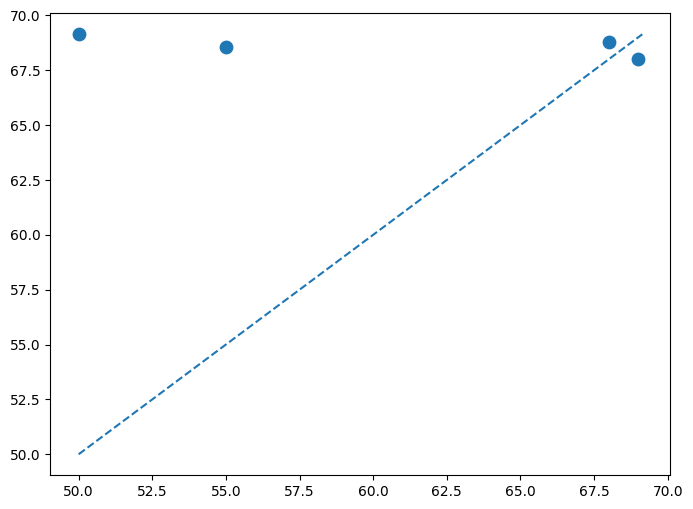

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize = (8,6))

#Comparar valores reales y predichos
plt.scatter(y_test, y_pred, s=80, label="Predicciones")

#Linea de referencia
minimo = min(y_test.min(), y_pred.min())
maximo = max(y_test.max(), y_pred.max())

plt.plot(
    [minimo,maximo],
    [minimo,maximo],
    linestyle = "--",
    label = "Predicción perfecta"
)

## 7. Predicción para un nuevo asteroide

Se utilizará el modelo entrenado para estimar el potencial de recursos de un nuevo candidato a minería espacial. Para ello, se introducirán sus características de distancia y costo estimado.

El modelo procesará estos datos y generará una predicción numérica. Este resultado permitirá ilustrar cómo un modelo de regresión puede apoyar la evaluación preliminar de candidatos. La estimación es orientativa, depende de los datos sintéticos empleados durante el entrenamiento y no representa una medición real de los recursos de un asteroide.

In [7]:

# Características de un nuevo asteroide candidato
nuevo_asteroide = pd.DataFrame({
    "distancia": [4],
    "costo": [50]
})

# Predecir su potencial de recursos
potencial_predicho = modelo.predict(nuevo_asteroide)[0]

print("Nuevo candidato: Asteroide X")
print("Distancia:", nuevo_asteroide.loc[0, "distancia"])
print("Costo estimado:", nuevo_asteroide.loc[0, "costo"])
print(f"Potencial de recursos predicho: {potencial_predicho:.2f}")

Nuevo candidato: Asteroide X
Distancia: 4
Costo estimado: 50
Potencial de recursos predicho: 67.95


## 8. Conclusiones

En este pipeline se implementó un modelo de regresión lineal para estimar el potencial de recursos de asteroides a partir de dos variables de entrada: la distancia y el costo estimado de la misión.

El proceso incluyó la preparación de un conjunto de datos sintéticos, la división de los registros en conjuntos de entrenamiento y prueba, el entrenamiento del modelo, la evaluación mediante las métricas MAE, MSE y R², y la visualización de los valores reales frente a las predicciones. Finalmente, se utilizó el modelo para estimar el potencial de recursos de un nuevo candidato.

Este ejercicio demuestra cómo el aprendizaje automático puede utilizarse para generar estimaciones que apoyen la evaluación preliminar de alternativas de minería espacial. Sin embargo, los resultados deben interpretarse con cautela: los datos son simulados, el conjunto de datos es pequeño y la regresión lineal tiene limitaciones para representar relaciones complejas. Por tanto, este modelo es una demostración académica y no permite determinar el valor real de los recursos de un asteroide.

En conjunto, el pipeline ilustra las etapas fundamentales de un proceso de aprendizaje automático: preparación de datos, entrenamiento, evaluación, visualización y predicción.